# 11 - So sánh các model trên Diabetes prediction dataset

So sánh DecisionTree, RandomForest, SVM và NaiveBayes trên cùng một stratified sample 10.000 dùng, cùng một train/test split và cùng bộ metric.

## 1. Load data và EDA ngắn

In [1]:
from pathlib import Path
import csv
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'diabetes.csv'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
RANDOM_STATE = 24

df = pd.read_csv(DATA_PATH)
print('Shape ban đầu:', df.shape)
print('Số dòng trùng lặp:', int(df.duplicated().sum()))
df = df.drop_duplicates().reset_index(drop=True)
print('Shape sau khi bỏ trùng:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Target distribution:')
print(df['diabetes'].value_counts(normalize=True).rename('proportion'))


Shape ban đầu: (100000, 9)
Số dòng trùng lặp: 3854
Shape sau khi bỏ trùng: (96146, 9)
Missing values: 0
Target distribution:
diabetes
0    0.91178
1    0.08822
Name: proportion, dtype: float64


## 2. Lấy mẫu và tiền xử lý

Theo phần ghi đè của PLAN, dùng cùng một mẫu phân tầng 10.000 để các model được so sánh công bằng và tránh chi phí quá lớn của SVM trên toàn bộ dữ liệu. Bỏ `diabetes` khỏi feature; `gender` và `smoking_history` được OneHotEncoder, các cột số được điền median. `class_weight=balanced` được dùng cho các model phân loại để chú ý lớp dương mất cân bằng.

In [2]:
sample_df, _ = train_test_split(
    df, train_size=10000, stratify=df['diabetes'], random_state=RANDOM_STATE
)
sample_df = sample_df.reset_index(drop=True)
X = sample_df.drop(columns=['diabetes'])
y = sample_df['diabetes'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

categorical_features = ['gender', 'smoking_history']
numeric_features = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'hypertension', 'heart_disease']
preprocess = ColumnTransformer([
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), categorical_features),
    ('num', SimpleImputer(strategy='median'), numeric_features),
])

models = {
    'DecisionTree': Pipeline([
        ('preprocess', preprocess),
        ('model', DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
    'RandomForest': Pipeline([
        ('preprocess', preprocess),
        ('model', RandomForestClassifier(n_estimators=150, max_depth=16, min_samples_leaf=3, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
    'SVM': Pipeline([
        ('preprocess', preprocess),
        ('scale', StandardScaler()),
        ('model', SVC(C=1, kernel='rbf', gamma='scale', class_weight='balanced', probability=True, random_state=RANDOM_STATE)),
    ]),
    'NaiveBayes': Pipeline([
        ('preprocess', preprocess),
        ('model', GaussianNB()),
    ]),
}


## 3. Train và Đánh giá cùng một bộ metric

In [3]:
results = []
predictions = {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]
    predictions[name] = pred
    result = {
        'notebook': '11_compare_models', 'dataset': 'diabetes.csv (stratified sample 10000)', 'model': name,
        'best_params': str(pipeline.named_steps['model'].get_params()),
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_test, prob),
    }
    results.append(result)
results_df = pd.DataFrame(results).sort_values('roc_auc', ascending=False).reset_index(drop=True)
print(results_df[['model', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']].round(4).to_string(index=False))


       model  accuracy  precision  recall     f1  roc_auc
RandomForest    0.9545     0.7249  0.7784 0.7507   0.9717
DecisionTree    0.8975     0.4592  0.9261 0.6139   0.9697
         SVM    0.8900     0.4375  0.8750 0.5833   0.9523
  NaiveBayes    0.8625     0.3714  0.8125 0.5098   0.9065


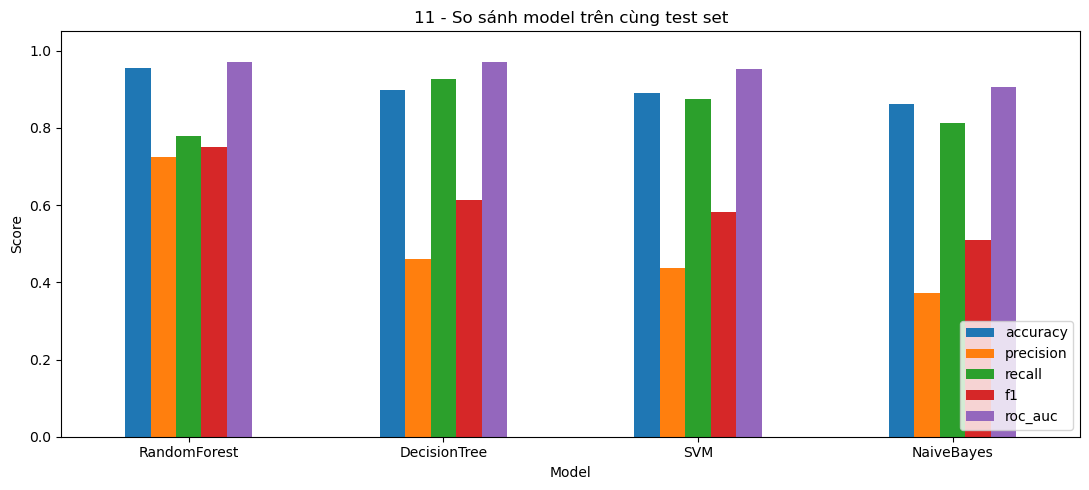

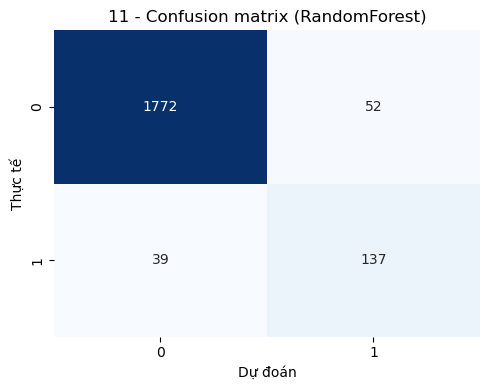

In [4]:
plot_df = results_df.set_index('model')[['accuracy', 'precision', 'recall', 'f1', 'roc_auc']]
ax = plot_df.plot(kind='bar', figsize=(11, 5), ylim=(0, 1.05), rot=0)
ax.set_title('11 - So sánh model trên cùng test set')
ax.set_ylabel('Score')
ax.set_xlabel('Model')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIGURES / '11_compare_models_metrics.png', dpi=150)
plt.show()

best_model = results_df.iloc[0]['model']
cm = confusion_matrix(y_test, predictions[best_model])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title(f'11 - Confusion matrix ({best_model})')
plt.tight_layout()
plt.savefig(FIGURES / '11_compare_models_confusion_matrix.png', dpi=150)
plt.show()


## 4. Nhận xét

Các model được fit và đánh giá trên cùng split. Với dữ liệu mất cân bằng, ROC AUC, recall và F1 của lớp 1 quan trọng hơn accuracy đơn thuần. Model đứng đầu bảng theo ROC AUC là lựa chọn tốt nhất trong thí nghiệm này; nếu model có recall cao nhưng precision thấp, đó là đánh đổi do `class_weight=balanced`. Kết quả có thể thay đổi nếu đổi random seed, nhưng giả định về split trong notebook là cố định.

In [5]:
summary_path = FIGURES / 'results_summary.csv'
fieldnames = ['notebook', 'dataset', 'model', 'best_params', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']
existing = []
if summary_path.exists():
    with summary_path.open(newline='', encoding='utf-8') as f:
        existing = [r for r in csv.DictReader(f) if r.get('notebook') != '11_compare_models']
with summary_path.open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(existing)
    writer.writerows(results)
print(results_df[['notebook', 'dataset', 'model', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']].round(4).to_string(index=False))


         notebook                                dataset        model  accuracy  precision  recall     f1  roc_auc
11_compare_models diabetes.csv (stratified sample 10000) RandomForest    0.9545     0.7249  0.7784 0.7507   0.9717
11_compare_models diabetes.csv (stratified sample 10000) DecisionTree    0.8975     0.4592  0.9261 0.6139   0.9697
11_compare_models diabetes.csv (stratified sample 10000)          SVM    0.8900     0.4375  0.8750 0.5833   0.9523
11_compare_models diabetes.csv (stratified sample 10000)   NaiveBayes    0.8625     0.3714  0.8125 0.5098   0.9065
